# PHẦN 1 — KỸ THUẬT 1: CLAHE
**Cân bằng lược đồ xám thích nghi có giới hạn tương phản**  
Mã môn: 121036 — Xử lý ảnh và Thị giác máy tính

## 1. Cài đặt 3 hàm cốt lõi

In [26]:
import numpy as np
import matplotlib.pyplot as plt

L = 256


def clip_histogram(hist, clip_limit):
    """Cắt và phân phối lại lược đồ. hist: mảng (L,) số nguyên.
    Trả về mảng (L,) đã cắt, tổng không đổi."""
    h = hist.astype(np.int64)
    limit = int(clip_limit)
    if limit < 1:
        limit = 1
    excess = np.sum(np.maximum(h - limit, 0))
    h = np.minimum(h, limit)

    # phân phối đều phần dư cho L mức xám
    h += int(excess // L)
    rem = int(excess % L)
    h[:rem] += 1
    return h


def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    """Trả về mảng (Gy, Gx, L) uint8: bảng tra của từng ô."""
    H, W = img.shape
    Gy, Gx = grid
    luts = np.zeros((Gy, Gx, L), dtype=np.uint8)

    for i in range(Gy):
        y0 = i * H // Gy
        y1 = (i + 1) * H // Gy
        for j in range(Gx):
            x0 = j * W // Gx
            x1 = (j + 1) * W // Gx
            tile = img[y0:y1, x0:x1]

            n_pixels = tile.size
            hist = np.bincount(tile.ravel(), minlength=L).astype(np.int64)

            cl = max(1, int(round(clip_limit * (n_pixels / float(L)))))
            hist = clip_histogram(hist, cl)

            cdf = np.cumsum(hist)
            nz = cdf[cdf > 0]
            cdf_min = nz[0] if nz.size > 0 else 0
            denom = n_pixels - cdf_min
            if denom <= 0:
                lut = np.arange(L, dtype=np.uint8)
            else:
                lut = np.clip(np.round((cdf - cdf_min) / denom * 255.0), 0, 255).astype(np.uint8)
            luts[i, j] = lut

    return luts


def clahe(img, grid=(8, 8), clip_limit=2.0):
    """CLAHE đầy đủ. img: (H, W) uint8. Trả về (H, W) uint8."""
    H, W = img.shape
    Gy, Gx = grid
    luts = build_tile_luts(img, grid, clip_limit)

    if Gy == 1 and Gx == 1:
        return luts[0, 0][img]

    # toạ độ tâm các ô
    cy = np.array([(i * H // Gy + (i + 1) * H // Gy - 1) / 2.0 for i in range(Gy)])
    cx = np.array([(j * W // Gx + (j + 1) * W // Gx - 1) / 2.0 for j in range(Gx)])

    yy, xx = np.mgrid[0:H, 0:W]

    ty = np.searchsorted(cy, yy.ravel(), side='right') - 1
    tx = np.searchsorted(cx, xx.ravel(), side='right') - 1
    ty = np.clip(ty, 0, max(0, Gy - 2))
    tx = np.clip(tx, 0, max(0, Gx - 2))

    dy = cy[ty + 1] - cy[ty] if Gy > 1 else 1.0
    dx = cx[tx + 1] - cx[tx] if Gx > 1 else 1.0
    fy = np.clip((yy.ravel() - cy[ty]) / dy, 0.0, 1.0) if Gy > 1 else np.zeros(H * W)
    fx = np.clip((xx.ravel() - cx[tx]) / dx, 0.0, 1.0) if Gx > 1 else np.zeros(H * W)

    ty1 = np.minimum(ty + 1, Gy - 1)
    tx1 = np.minimum(tx + 1, Gx - 1)
    v = img.ravel()

    # nội suy song tuyến trên 4 giá trị LUT của 4 tâm ô lân cận
    f00 = luts[ty,  tx,  v].astype(np.float64)
    f10 = luts[ty1, tx,  v].astype(np.float64)
    f01 = luts[ty,  tx1, v].astype(np.float64)
    f11 = luts[ty1, tx1, v].astype(np.float64)

    out = (1.0 - fy) * (1.0 - fx) * f00 + \
          (1.0 - fy) * fx         * f01 + \
          fy         * (1.0 - fx) * f10 + \
          fy         * fx         * f11

    return np.round(out).astype(np.uint8).reshape(H, W)

## 2. Kiểm thử cơ bản

In [27]:
rng = np.random.default_rng(42)

# 1. Kiểm tra bảo toàn tổng histogram sau khi cắt
h_test = rng.integers(0, 500, size=256)
h_clipped = clip_histogram(h_test, clip_limit=200)
assert h_clipped.sum() == h_test.sum(), "Lỗi: Tổng histogram thay đổi!"
print(f"[PASS] clip_histogram: tổng trước = {h_test.sum()}, tổng sau = {h_clipped.sum()}")

# 2. Kiểm tra kích thước và kiểu dữ liệu bảng tra LUT
img_test = rng.integers(0, 256, size=(103, 157), dtype=np.uint8)
luts_test = build_tile_luts(img_test, grid=(8, 8), clip_limit=2.0)
assert luts_test.shape == (8, 8, 256) and luts_test.dtype == np.uint8
print(f"[PASS] build_tile_luts: shape = {luts_test.shape}, dtype = {luts_test.dtype}")

# 3. Kiểm tra CLAHE trên ảnh kích thước lẻ (không chia hết cho grid)
out_test = clahe(img_test, grid=(8, 8), clip_limit=2.0)
assert out_test.shape == img_test.shape and out_test.dtype == np.uint8
print(f"[PASS] clahe (103x157): shape = {out_test.shape}, dtype = {out_test.dtype}")

# 4. Kiểm tra CLAHE trên ảnh kích thước chẵn
img_even = rng.integers(0, 256, size=(256, 256), dtype=np.uint8)
out_even = clahe(img_even, grid=(8, 8), clip_limit=2.0)
assert out_even.shape == (256, 256) and out_even.dtype == np.uint8
print(f"[PASS] clahe (256x256): shape = {out_even.shape}, dtype = {out_even.dtype}")

[PASS] clip_histogram: tổng trước = 64196, tổng sau = 64196
[PASS] build_tile_luts: shape = (8, 8, 256), dtype = uint8
[PASS] clahe (103x157): shape = (103, 157), dtype = uint8
[PASS] clahe (256x256): shape = (256, 256), dtype = uint8


---
## 3. Thí nghiệm minh họa

### Có dùng AI hỗ trợ
Công cụ: Gemini  
Mục đích: Sinh bộ ảnh thử nghiệm gồm: (1) ảnh có ánh sáng không đều kèm vùng phẳng nhiễu và các chi tiết ẩn ở vùng tối/sáng để khảo sát tham số và chứng minh CLAHE thắng; (2) ảnh ngược sáng có nền tối rộng nhiễm nhiễu cảm biến để minh họa trường hợp CLAHE thua.  
Prompt:
> Viết code bằng NumPy tạo 2 ảnh xám uint8 kích thước 256x256: ảnh 1 có độ sáng chênh lệch mạnh (nửa tối, nửa sáng), có vùng nền phẳng nhiễu nhẹ và các họa tiết hình học mờ ở cả hai vùng; ảnh 2 là ảnh silhouette ngược sáng có nền tối phẳng rộng kèm nhiễu nhẹ để minh họa CLAHE khuếch đại nhiễu nền so với biến đổi gamma.  

Đã sửa lại những gì: Đã kiểm tra quy ước chỉ số mảng img[y, x], điều chỉnh biên độ chi tiết và mức nhiễu để thể hiện rõ sự khác biệt giữa các phương pháp.

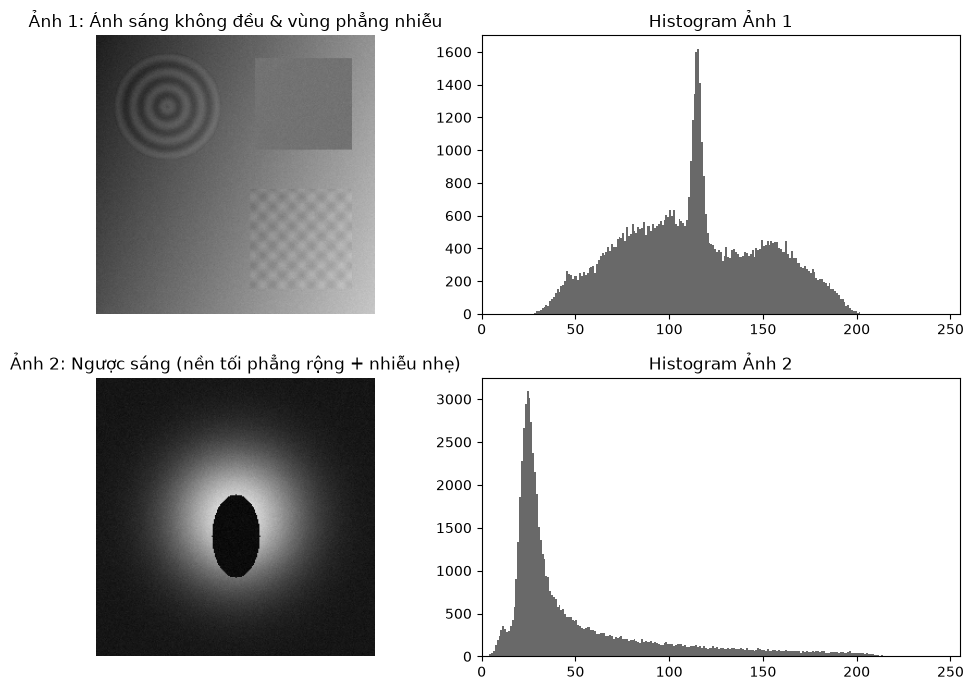

In [28]:
np.random.seed(42)
H, W = 256, 256
yy, xx = np.mgrid[0:H, 0:W]

# 1. Ảnh thử nghiệm chính (ánh sáng không đều + chi tiết vùng tối/sáng + vùng phẳng có nhiễu)
illum = 30.0 + 170.0 * (xx / float(W) * 0.7 + yy / float(H) * 0.3)
details = np.zeros((H, W), dtype=np.float64)

# Các vòng tròn đồng tâm mờ ở góc trên-trái (vùng tối)
r1 = np.sqrt((yy - 65)**2 + (xx - 65)**2)
details[r1 < 50] = 14.0 * np.sin(r1[r1 < 50] * 0.45)

# Lưới sọc caro mờ ở góc dưới-phải (vùng sáng)
mask_box = (yy > 140) & (yy < 235) & (xx > 140) & (xx < 235)
details[mask_box] = 12.0 * (np.sin(yy[mask_box] * 0.35) * np.cos(xx[mask_box] * 0.35))

# Vùng phẳng ở góc trên-phải để quan sát nhiễu
mask_flat = (yy > 20) & (yy < 105) & (xx > 145) & (xx < 235)
illum[mask_flat] = 115.0

noise = np.random.normal(0, 2.5, size=(H, W))
img_uneven = np.clip(illum + details + noise, 0, 255).astype(np.uint8)

# 2. Ảnh thử nghiệm trường hợp CLAHE thua (ảnh silhouette nền tối phẳng rộng có nhiễu cảm biến)
img_lose = np.full((H, W), 22.0, dtype=np.float64)
# Vầng sáng dịu ở tâm và vật thể ngược sáng
dist_center = np.sqrt((yy - 128)**2 + (xx - 128)**2)
img_lose += 210.0 * np.exp(-(dist_center**2) / (2.0 * 42.0**2))
silhouette = ((yy - 145)**2 / 38.0**2 + (xx - 128)**2 / 22.0**2) <= 1.0
img_lose[silhouette] = 12.0
img_lose += np.random.normal(0, 3.2, size=(H, W))
img_lose = np.clip(img_lose, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(img_uneven, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title('Ảnh 1: Ánh sáng không đều & vùng phẳng nhiễu')
axes[0, 0].axis('off')
axes[0, 1].hist(img_uneven.ravel(), bins=256, range=(0, 256), color='dimgray')
axes[0, 1].set_title('Histogram Ảnh 1')
axes[0, 1].set_xlim(0, 255)

axes[1, 0].imshow(img_lose, cmap='gray', vmin=0, vmax=255)
axes[1, 0].set_title('Ảnh 2: Ngược sáng (nền tối phẳng rộng + nhiễu nhẹ)')
axes[1, 0].axis('off')
axes[1, 1].hist(img_lose.ravel(), bins=256, range=(0, 256), color='dimgray')
axes[1, 1].set_title('Histogram Ảnh 2')
axes[1, 1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

### 3.1. Khảo sát ảnh hưởng của tham số (`clip_limit` và `grid`)

### Có dùng AI hỗ trợ
Công cụ: Gemini  
Mục đích: Quét tham số `clip_limit` qua 4 giá trị [1.0, 2.0, 4.0, 8.0] và `grid` qua 4 giá trị [(2, 2), (4, 4), (8, 8), (16, 16)], hiển thị dạng lưới ảnh kèm histogram.  
Prompt:
> Viết code khảo sát hàm clahe trên img_uneven: (1) cố định grid=(8,8), quét clip_limit qua 4 giá trị [1.0, 2.0, 4.0, 8.0]; (2) cố định clip_limit=2.5, quét grid qua 4 giá trị [(2,2), (4,4), (8,8), (16,16)]. Vẽ lưới ảnh kết quả kèm histogram tương ứng.  

Đã sửa lại những gì: Đã kiểm tra quy ước chỉ số mảng img[y, x], bổ sung đủ 4 giá trị cho cả clip_limit và grid, tinh chỉnh lại bố cục subplot cho rõ nét.

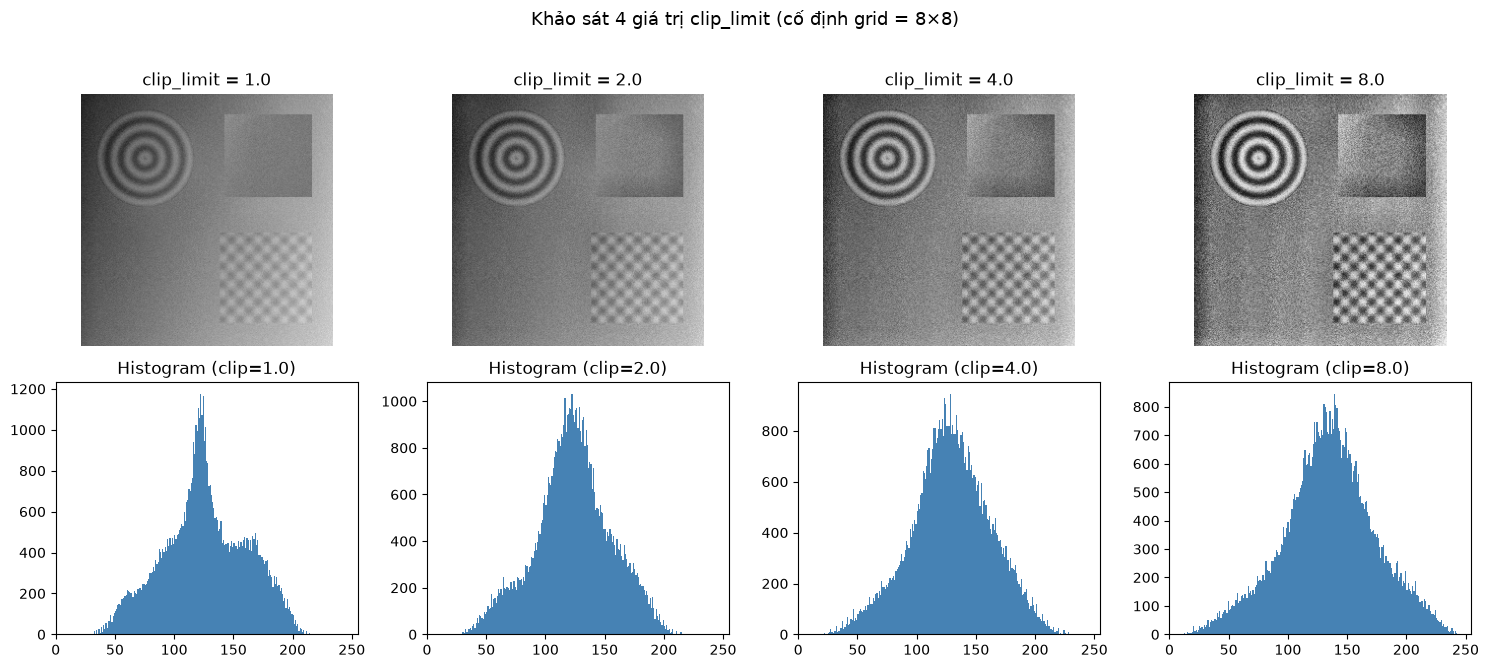

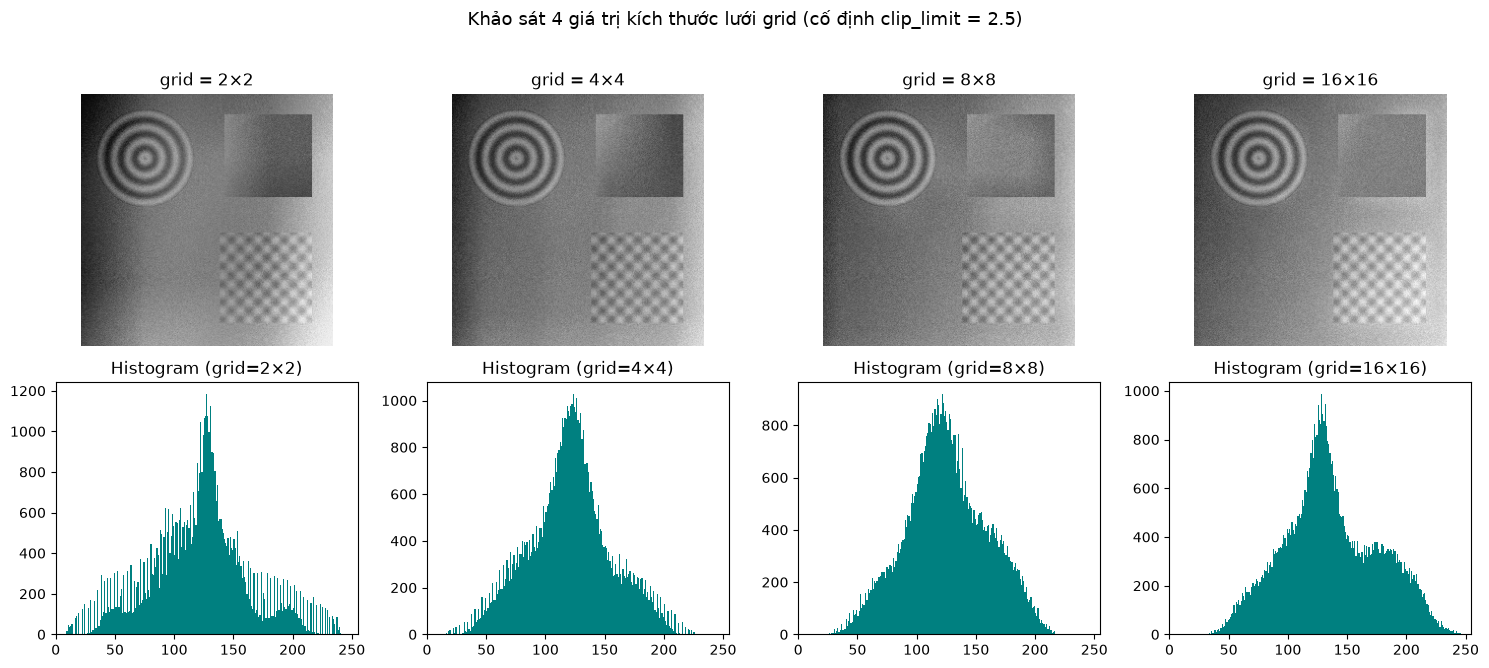

In [29]:
# (a1) Quét clip_limit qua 4 giá trị
clip_values = [1.0, 2.0, 4.0, 8.0]
fig, axes = plt.subplots(2, len(clip_values), figsize=(15, 6.5))

for k, cl in enumerate(clip_values):
    res = clahe(img_uneven, grid=(8, 8), clip_limit=cl)
    axes[0, k].imshow(res, cmap='gray', vmin=0, vmax=255)
    axes[0, k].set_title(f'clip_limit = {cl}')
    axes[0, k].axis('off')
    axes[1, k].hist(res.ravel(), bins=256, range=(0, 256), color='steelblue', edgecolor='none')
    axes[1, k].set_xlim(0, 255)
    axes[1, k].set_title(f'Histogram (clip={cl})')

plt.suptitle('Khảo sát 4 giá trị clip_limit (cố định grid = 8×8)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# (a2) Quét grid qua 4 giá trị
grid_values = [(2, 2), (4, 4), (8, 8), (16, 16)]
fig, axes = plt.subplots(2, len(grid_values), figsize=(15, 6.5))

for k, g in enumerate(grid_values):
    res = clahe(img_uneven, grid=g, clip_limit=2.5)
    axes[0, k].imshow(res, cmap='gray', vmin=0, vmax=255)
    axes[0, k].set_title(f'grid = {g[0]}×{g[1]}')
    axes[0, k].axis('off')
    axes[1, k].hist(res.ravel(), bins=256, range=(0, 256), color='teal', edgecolor='none')
    axes[1, k].set_xlim(0, 255)
    axes[1, k].set_title(f'Histogram (grid={g[0]}×{g[1]})')

plt.suptitle('Khảo sát 4 giá trị kích thước lưới grid (cố định clip_limit = 2.5)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Nhận xét ảnh hưởng của tham số:**
- **Tham số `clip_limit`:** Khi `clip_limit = 1.0`, ngưỡng cắt bằng đúng mức trung bình $N_{tile}/L$, lược đồ gần như bị san phẳng nên ảnh đầu ra giữ nguyên độ tương phản thấp như ảnh gốc và vùng phẳng rất mịn. Khi tăng lên `2.0` – `4.0`, chi tiết ẩn ở cả góc tối (vòng tròn đồng tâm) và góc sáng (ô caro) nổi lên rõ rệt trong khi nhiễu ở ô phẳng góc trên-phải vẫn được kiểm soát. Khi `clip_limit = 8.0`, độ dốc bảng tra lớn làm các hạt nhiễu ở vùng phẳng bị khuếch đại mạnh (rỗ mặt).
- **Tham số `grid`:** Với `grid = (2, 2)`, ô quá lớn nên bảng tra vẫn mang tính toàn cục, chưa tách rõ được các vân mờ nằm trên nền sáng-tối chênh lệch. Khi tăng lên `(8, 8)` và `(16, 16)`, kích thước ô đủ nhỏ để thích nghi theo độ sáng từng vùng, làm nổi rõ chi tiết cục bộ mà không xuất hiện đường ranh giới ô vuông nhờ bước nội suy song tuyến trên LUT.

### 3.2. So sánh CLAHE với các thuật toán đã học (Trường hợp CLAHE thắng và CLAHE thua)

### Có dùng AI hỗ trợ
Công cụ: Gemini  4 argon 
Mục đích: Cài đặt các hàm cơ sở (Kéo giãn tuyến tính, Gamma, HE toàn cục bằng NumPy) và đặt cạnh CLAHE kèm histogram trên 2 ảnh: ảnh CLAHE thắng rõ rệt và ảnh CLAHE thua.  
Prompt:
> Viết các hàm linear_stretch, gamma_correction, global_he bằng NumPy thuần. Sau đó vẽ lưới 2x4 đặt cạnh nhau 4 phương pháp (Kéo giãn tuyến tính, Gamma, HE toàn cục, CLAHE) kèm histogram bên dưới trên 2 ảnh: img_uneven (CLAHE thắng) và img_lose (CLAHE thua).  

Đã sửa lại những gì: Đã kiểm tra công thức tính CDF của HE toàn cục và tham số gamma, căn chỉnh lại trục biểu đồ histogram cho đồng bộ.

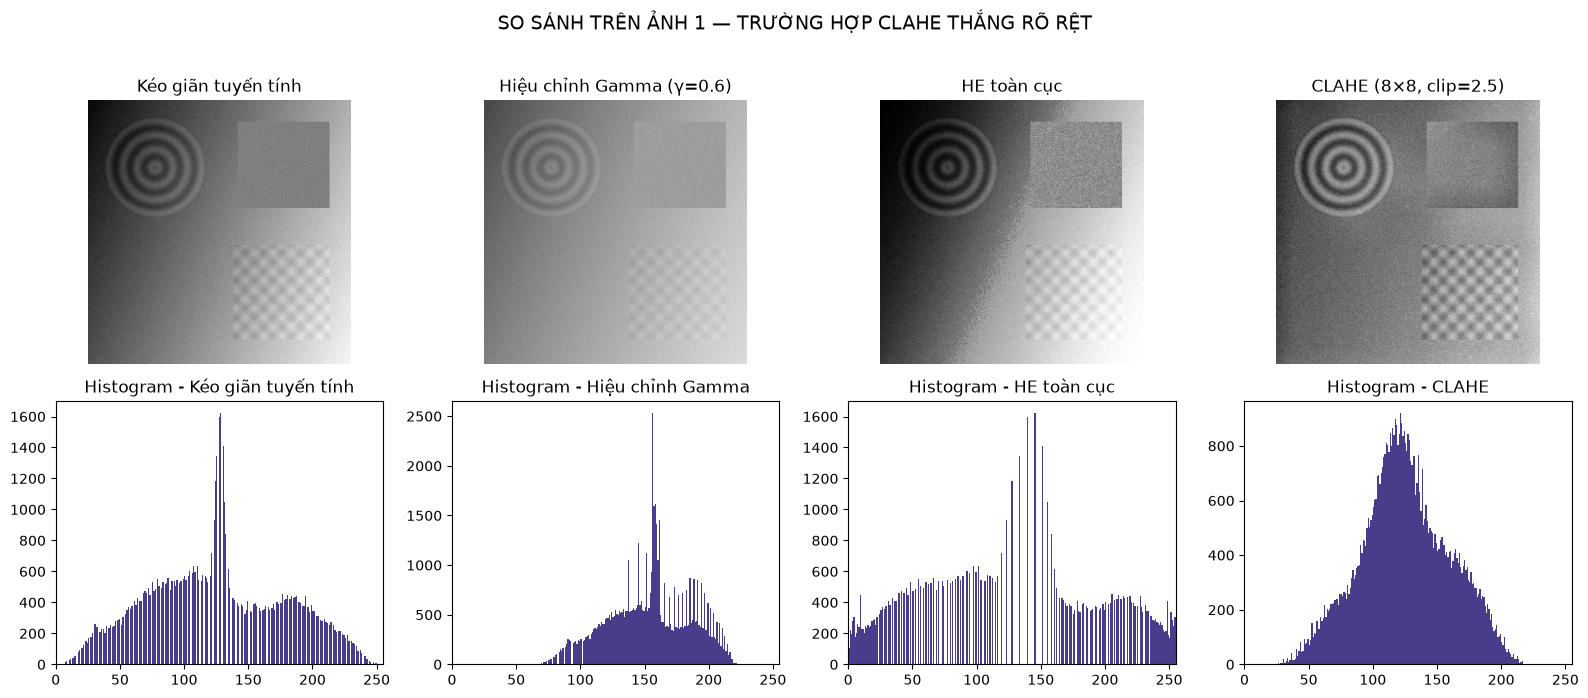

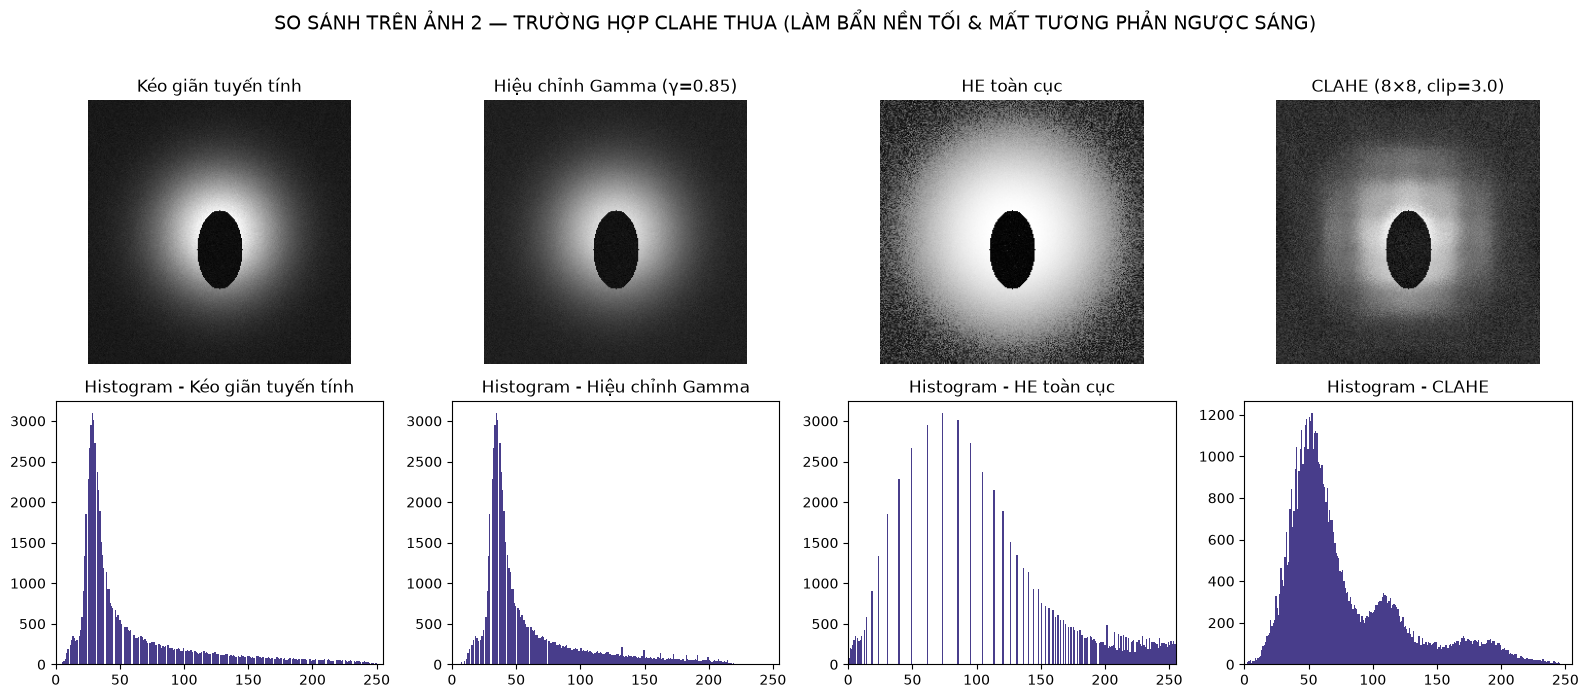

In [30]:
def linear_stretch(img):
    vmin, vmax = float(img.min()), float(img.max())
    if vmax == vmin:
        return img.copy()
    return np.round((img.astype(np.float64) - vmin) / (vmax - vmin) * 255.0).astype(np.uint8)


def gamma_correction(img, gamma=0.6):
    norm = img.astype(np.float64) / 255.0
    return np.round((norm ** gamma) * 255.0).astype(np.uint8)


def global_he(img):
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = np.cumsum(hist)
    cdf_min = cdf[cdf > 0][0]
    denom = img.size - cdf_min
    if denom <= 0:
        return img.copy()
    lut = np.round((cdf - cdf_min) / denom * 255.0).astype(np.uint8)
    return lut[img]


def compare_four_methods(img, title_prefix, gamma_val=0.6, grid=(8, 8), clip_limit=2.5):
    methods = [
        ('Kéo giãn tuyến tính', linear_stretch(img)),
        (f'Hiệu chỉnh Gamma (γ={gamma_val})', gamma_correction(img, gamma=gamma_val)),
        ('HE toàn cục', global_he(img)),
        (f'CLAHE ({grid[0]}×{grid[1]}, clip={clip_limit})', clahe(img, grid=grid, clip_limit=clip_limit))
    ]
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.8))
    for k, (name, res) in enumerate(methods):
        axes[0, k].imshow(res, cmap='gray', vmin=0, vmax=255)
        axes[0, k].set_title(name)
        axes[0, k].axis('off')
        axes[1, k].hist(res.ravel(), bins=256, range=(0, 256), color='darkslateblue', edgecolor='none')
        axes[1, k].set_xlim(0, 255)
        axes[1, k].set_title(f'Histogram - {name.split("(")[0].strip()}')
    plt.suptitle(title_prefix, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()


# Trường hợp 1: Ảnh CLAHE thắng rõ rệt
compare_four_methods(img_uneven, 'SO SÁNH TRÊN ẢNH 1 — TRƯỜNG HỢP CLAHE THẮNG RÕ RỆT', gamma_val=0.6, grid=(8, 8), clip_limit=2.5)

# Trường hợp 2: Ảnh CLAHE thua (so với Kéo giãn tuyến tính / Gamma)
compare_four_methods(img_lose, 'SO SÁNH TRÊN ẢNH 2 — TRƯỜNG HỢP CLAHE THUA (LÀM BẨN NỀN TỐI & MẤT TƯƠNG PHẢN NGƯỢC SÁNG)', gamma_val=0.85, grid=(8, 8), clip_limit=3.0)

**Nhận xét kết quả so sánh:**
1. **Trên Ảnh 1 (Trường hợp CLAHE thắng rõ rệt):**
   - **Kéo giãn tuyến tính & Hiệu chỉnh Gamma:** Vì toàn ảnh đã có đủ điểm tối và điểm sáng ở hai đầu nên kéo giãn tuyến tính hầu như không làm tăng tương phản cục bộ; Gamma chỉ nâng sáng tổng thể nhưng các vòng tròn đồng tâm ở vùng tối và lưới caro ở vùng sáng vẫn rất mờ.
   - **HE toàn cục:** Dùng chung 1 bảng tra cho toàn ảnh nên vùng sáng bị cháy trắng, vùng tối bị bết và vùng phẳng góc trên-phải bị nhiễu hạt rất nặng (cột histogram cao vọt ở mức trung bình làm bảng tra dốc đứng).
   - **CLAHE:** Nhờ chia lưới $8\times 8$ và giới hạn ngưỡng cắt, cả họa tiết ở vùng tối lẫn vùng sáng đều hiện rõ nét, đồng thời vùng phẳng không bị rỗ nhiễu.
2. **Trên Ảnh 2 (Trường hợp CLAHE thua):**
   - Đây là ảnh ngược sáng (silhouette) có vùng nền tối chiếm diện tích lớn và chứa nhiễu cảm biến nhẹ. **Kéo giãn tuyến tính** và **Hiệu chỉnh Gamma ($\gamma=0.85$)** bảo toàn tốt nền đen sâu, giữ được hiệu ứng thị giác tự nhiên và độ tương phản giữa chủ thể ngược sáng với hào quang phía sau.
   - Ngược lại, **CLAHE** (và cả HE toàn cục) cố gắng cân bằng cục bộ từng ô trên nền tối, vô tình kéo sáng nền đen lên thành xám loang lổ, khuếch đại nhiễu nền và tạo quầng sáng giả (halo) quanh biên chủ thể.